# Lamb half-space reference — notebook with exports

The generic loading choices are `ricker`, `rectangle`, and `three_step`. The defaults are based on Kim and Bathe (2021); article-specific inputs are still available with `Source.from_demo(...)`.

**Each runnable example shows its export commands explicitly:** the source plot and its two CSVs, receiver displacement histories, a surface spatial profile, and optional paper-demo source files. The PNGs are saved **before** `plt.show()`, so they remain viewable in Jupyter.

The Green-function solver is for **surface points** (`y=0`) in a homogeneous plane-strain half-space. The CSV files can be loaded directly into ParaView; no VTKHDF exporter is used.

In [1]:
%matplotlib inline
import json
from dataclasses import asdict
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

from lamb_surface_exact import Source, ElasticHalfspace, SurfaceStepGreen
from run import export_load, write_receivers, write_surface_snapshot

out = Path("notebook_output")
out.mkdir(parents=True, exist_ok=True)

# Choose one generic input. You can use "ricker" or "rectangle" instead.
source = Source(kind="three_step")
# Example of original article parameters: Source.from_demo("kwon_steps")

# Export the actual source parameters for reproducibility.
parameters_file = out / "source_parameters.json"
parameters_file.write_text(json.dumps(asdict(source), indent=2) + "\n", encoding="utf-8")
print("Source:", source)
print("Parameters saved to:", parameters_file.resolve())

Source: Source(kind='three_step', amplitude=2000000.0, ricker_frequency=10.0, ricker_shift=0.1, rectangle_start=0.0, rectangle_end=0.15, step_times=(0.0, 0.05, 0.1, 0.15), step_jumps=(1.0, -3.0, 3.0, -1.0))
Parameters saved to: /home/shion/Dropbox/src/lambAnalytical/notebook_output/source_parameters.json


## 1. Inspect loading in time and frequency domains

`export_load()` writes `load_time.csv` and `load_spectrum.csv`. The spectrum is the **analytical continuous-time Fourier transform** of the specified source, not an FFT of a truncated sample. In this notebook we set `plot=False` and explicitly save/show our own figure, so the figure is displayed by Jupyter's active backend.

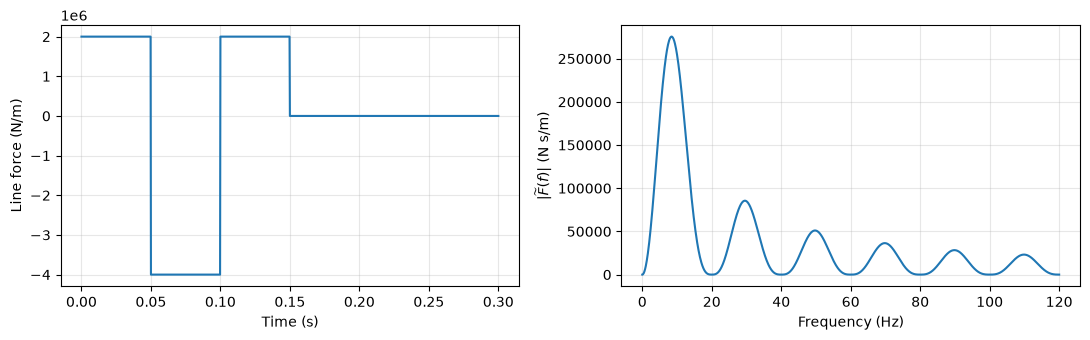

Exported:
  notebook_output/load_time.csv
  notebook_output/load_spectrum.csv
  notebook_output/load_inspection.png


In [2]:
# ---- CSV EXPORT: time-domain force and complex frequency spectrum ----
export_load(out, source, duration=0.30, dt=0.00025,
            fmax=120.0, nfreq=1201, plot=False)
load_time_csv = out / "load_time.csv"
load_spectrum_csv = out / "load_spectrum.csv"

# Compute plotted samples using the identical grids.
t_load = np.arange(1201) * 0.00025
freq = np.linspace(0.0, 120.0, 1201)
force = source.force(t_load)
spectrum = source.spectrum(freq)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(t_load, force)
axes[0].set(xlabel="Time (s)", ylabel="Line force (N/m)")
axes[1].plot(freq, np.abs(spectrum))
axes[1].set(xlabel="Frequency (Hz)", ylabel=r"$|\widetilde F(f)|$ (N s/m)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()

# ---- PNG EXPORT: save before showing, to preserve Jupyter display ----
load_plot = out / "load_inspection.png"
fig.savefig(load_plot, dpi=180, bbox_inches="tight")
plt.show()
print("Exported:", load_time_csv, load_spectrum_csv, load_plot, sep="\n  ")

## 2. Surface receiver time histories

`receivers.csv` is a long-form table containing all receivers at every time. For convenience, the notebook additionally exports **one CSV per receiver**, with columns `time_s,ux_m,uy_m`, which is particularly straightforward to plot in ParaView.

The step response uses analytical time shifts and does **not** need inverse temporal FFT. The Ricker response uses a Green-function convolution.

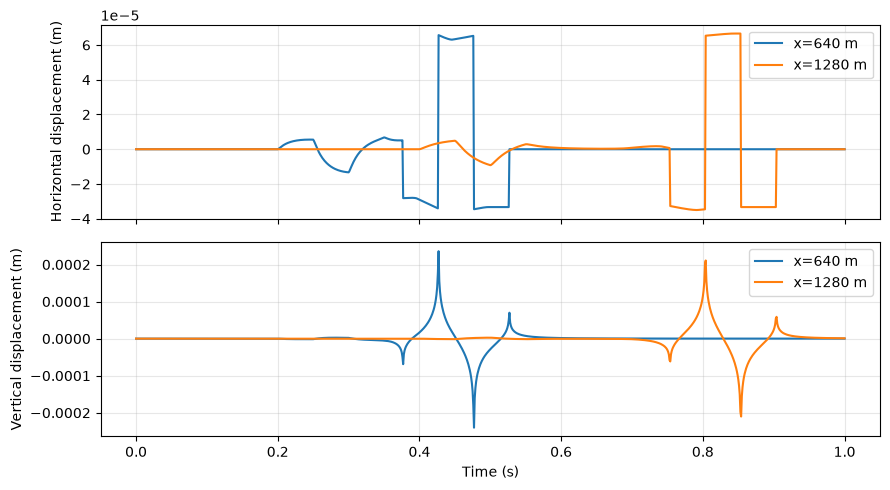

Exported:
  notebook_output/receivers.csv
  notebook_output/receiver_x640m.csv
  notebook_output/receiver_x1280m.csv
  notebook_output/receivers.png


In [3]:
material = ElasticHalfspace()
times = np.arange(1001) * 0.001
receivers = np.array([640.0, 1280.0])
# The Green-function tabulation is reused in subsequent cells.
G = SurfaceStepGreen(material, max_tau=160.0)
u = G.receivers(receivers, times, source)  # shape: (nt, nreceivers, 2)

# ---- CSV EXPORT: all receivers in one table ----
receivers_csv = out / "receivers.csv"
write_receivers(receivers_csv, times, receivers, u)

# ---- CSV EXPORT: easy-to-plot separate time series for each receiver ----
receiver_csvs = []
for j, x in enumerate(receivers):
    filepath = out / f"receiver_x{x:g}m.csv"
    np.savetxt(filepath,
               np.column_stack((times, u[:, j, 0], u[:, j, 1])),
               delimiter=",", header="time_s,ux_m,uy_m", comments="", fmt="%.16g")
    receiver_csvs.append(filepath)

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
for j, x in enumerate(receivers):
    axes[0].plot(times, u[:, j, 0], label=f"x={x:g} m")
    axes[1].plot(times, u[:, j, 1], label=f"x={x:g} m")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Horizontal displacement (m)")
axes[1].set(xlabel="Time (s)", ylabel="Vertical displacement (m)")
fig.tight_layout()

# ---- PNG EXPORT ----
receiver_plot = out / "receivers.png"
fig.savefig(receiver_plot, dpi=180, bbox_inches="tight")
plt.show()
print("Exported:", receivers_csv, *receiver_csvs, receiver_plot, sep="\n  ")

## 3. Spatial displacement profile at an arbitrary time

`G.profile` evaluates displacements directly at `snapshot_time`; there is **no temporal interpolation** of computed time histories. The CSV stores the surface position, sampling time, and the two displacement components.

Avoid sampling the ideal source position `x=0` and take care near physical Rayleigh-wave singularities.

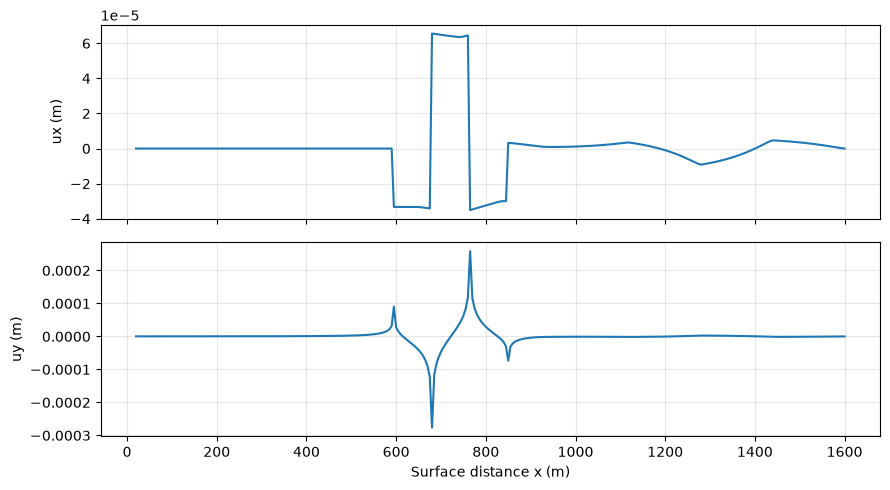

Exported:
  notebook_output/surface_t0.50023.csv
  notebook_output/surface_t0.50023.png


In [4]:
xline = np.arange(20.0, 1600.01, 5.0)
snapshot_time = 0.50023
us = G.profile(xline, snapshot_time, source, dt=0.001)

# ---- CSV EXPORT: spatial line values, directly readable in ParaView ----
snapshot_csv = out / f"surface_t{snapshot_time:.5f}.csv"
write_surface_snapshot(snapshot_csv, xline, snapshot_time, us)

fig, axes = plt.subplots(2, 1, figsize=(9, 5), sharex=True)
axes[0].plot(xline, us[:, 0])
axes[0].set_ylabel("ux (m)")
axes[1].plot(xline, us[:, 1])
axes[1].set(xlabel="Surface distance x (m)", ylabel="uy (m)")
for ax in axes:
    ax.grid(alpha=0.3)
fig.tight_layout()

# ---- PNG EXPORT ----
snapshot_plot = out / f"surface_t{snapshot_time:.5f}.png"
fig.savefig(snapshot_plot, dpi=180, bbox_inches="tight")
plt.show()
print("Exported:", snapshot_csv, snapshot_plot, sep="\n  ")

## 4. Optional: export load inspections for other presets and paper examples

This final example creates **only source preview CSVs**, without recalculating the elastodynamic response. The generic presets have no article prefix, while `Source.from_demo(...)` retains the published force definitions. Change or extend `cases` as needed.

ricker: notebook_output/load_examples/ricker/load_time.csv; notebook_output/load_examples/ricker/load_spectrum.csv
rectangle: notebook_output/load_examples/rectangle/load_time.csv; notebook_output/load_examples/rectangle/load_spectrum.csv
three_step: notebook_output/load_examples/three_step/load_time.csv; notebook_output/load_examples/three_step/load_spectrum.csv
kwon_steps: notebook_output/load_examples/kwon_steps/load_time.csv; notebook_output/load_examples/kwon_steps/load_spectrum.csv
kim_ricker: notebook_output/load_examples/kim_ricker/load_time.csv; notebook_output/load_examples/kim_ricker/load_spectrum.csv


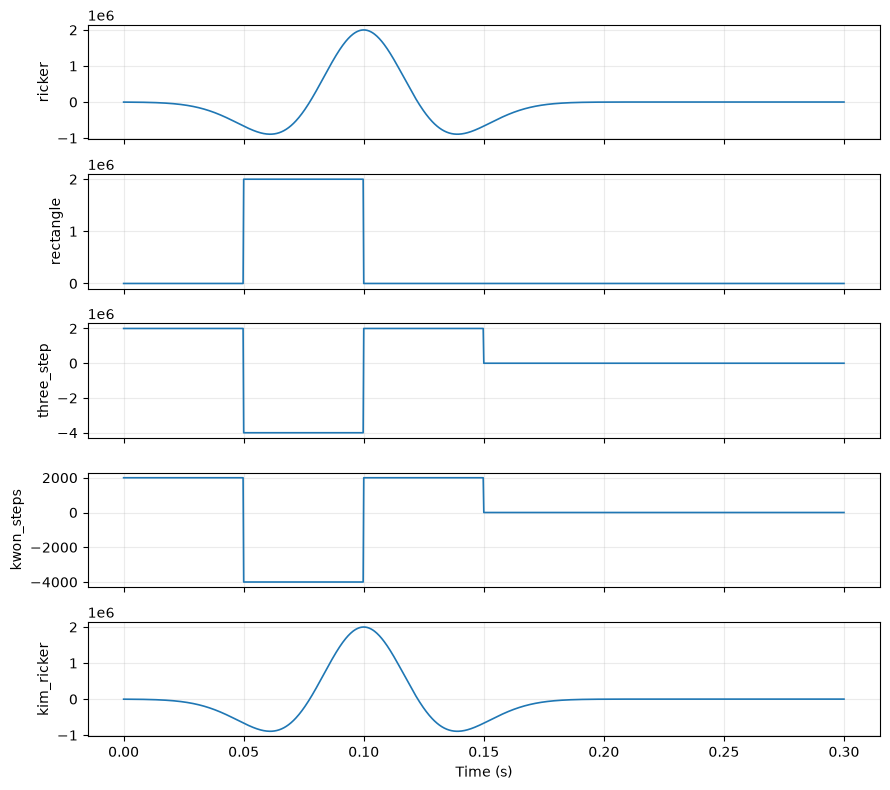

Exported: notebook_output/load_examples/preset_comparison.png


In [5]:
cases = {
    "ricker": Source(kind="ricker"),
    "rectangle": Source(kind="rectangle", rectangle_start=0.05, rectangle_end=0.10),
    "three_step": Source(kind="three_step"),
    "kwon_steps": Source.from_demo("kwon_steps"),
    "kim_ricker": Source.from_demo("kim_ricker"),
}

# ---- CSV EXPORT: each preset receives load_time.csv and load_spectrum.csv ----
for name, example_source in cases.items():
    case_dir = out / "load_examples" / name
    export_load(case_dir, example_source, duration=0.30, dt=0.00025,
                fmax=120.0, nfreq=1201, plot=False)
    print(f"{name}: {case_dir / 'load_time.csv'}; {case_dir / 'load_spectrum.csv'}")

# ---- PNG EXPORT: visual comparison of generic and article-specific load shapes ----
t_preview = np.arange(1201) * 0.00025
fig, axes = plt.subplots(len(cases), 1, figsize=(9, 8), sharex=True)
for ax, (name, example_source) in zip(axes, cases.items()):
    ax.plot(t_preview, example_source.force(t_preview), lw=1.2)
    ax.set_ylabel(name)
    ax.grid(alpha=0.25)
axes[-1].set_xlabel("Time (s)")
fig.tight_layout()
presets_plot = out / "load_examples" / "preset_comparison.png"
fig.savefig(presets_plot, dpi=180, bbox_inches="tight")
plt.show()
print("Exported:", presets_plot)

## Reading the exported CSV in ParaView

Use **File → Open → CSV Reader**. For receiver histories, open `receiver_x640m.csv` and plot `ux_m`/`uy_m` against `time_s`. For a spatial profile, open `surface_t0.50023.csv` and use **Table To Points**, assigning `x_m` to X and `y_depth_m` to Y (Z = 0), or plot `ux_m`/`uy_m` against `x_m` in a chart view. CSV does not automatically create a ParaView time-slider animation.

Exported files appear under the notebook's `notebook_output/` directory. Run `python verify.py` in the project directory to check the analytical solver's numerical tests.